# Lab: Build a dense variational autoencoder for faces

**Time:** 90–120 minutes  
**Prerequisites:** PyTorch, linear layers, probability basics, and gradient descent

In this lab you will turn an image into a *distribution* in latent space, sample from
that distribution with the reparameterization trick, and train a decoder using the
VAE objective. The network is deliberately fully connected: convolution is useful
for images, but it is not what makes a model a VAE.

By the end, you should be able to:

- distinguish a deterministic autoencoder from a VAE;
- parameterize $q_\phi(z\mid x)$ with $\mu$ and $\log\sigma^2$;
- implement $z=\mu+\sigma\odot\epsilon$ without breaking backpropagation;
- combine reconstruction and KL-divergence terms; and
- generate new faces by sampling $z\sim\mathcal N(0,I)$.


## 1. Environment and LFW data (10 minutes)

This notebook runs both on Kaggle and locally.

**On Kaggle:** create a notebook, choose **Add Input**, search for `LFW Dataset`, and
attach the dataset whose mounted folder is `/kaggle/input/lfw-dataset`. Upload this
notebook or open it from the course repository, then choose a GPU accelerator if one
is available. No path edit should be necessary.

**Locally:** download and extract LFW so the directory contains person folders and
`.jpg` files. Then either:

1. set the environment variable `LFW_DATASET_PATH` to the extracted directory; or
2. edit `LOCAL_DATASET_PATH` in the next cell.

The path may point either directly to `lfw-deepfunneled` or to a parent directory;
the discovery code searches below it. The notebook fails early with a useful message
if no images are found.


In [1]:
# Kaggle images normally include these packages. For a minimal local environment:
# %pip install torch torchvision matplotlib pandas scikit-learn pillow

import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 1e-3
BETA = 1.0
# Windows spawns DataLoader workers, which cannot import classes defined in a notebook.
NUM_WORKERS = 2 if torch.cuda.is_available() and os.name != "nt" else 0

# Change only this line for a local setup if LFW_DATASET_PATH is not set.
LOCAL_DATASET_PATH = Path("data/lfw-deepfunneled")

print(f"Running on {DEVICE}")


C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Running on cuda


In [2]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend([
            Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
            Path("/kaggle/input/lfw-dataset"),
        ])
    candidates.extend([
        LOCAL_DATASET_PATH.expanduser(),
        Path("lfw-deepfunneled"),
    ])

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


DATASET_ROOT = resolve_lfw_root()
image_paths = sorted(DATASET_ROOT.rglob("*.jpg"))
image_df = pd.DataFrame({
    "path": image_paths,
    "person": [path.parent.name for path in image_paths],
})

# Preserve the original notebook's balancing choice: remove identities with 25+
# photographs so a few celebrities do not dominate reconstruction training.
image_df = image_df.groupby("person", group_keys=False).filter(lambda rows: len(rows) < 25)
image_df = image_df.reset_index(drop=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Using {len(image_df):,} images from {image_df['person'].nunique():,} people")
image_df.head()


Dataset root: data\lfw-deepfunneled
Using 10,645 images from 5,707 people


,path,person
0,data\lfw-deepfunneled\Aaron_Eckhart\Aaron_Eckh...,Aaron_Eckhart
1,data\lfw-deepfunneled\Aaron_Guiel\Aaron_Guiel_...,Aaron_Guiel
2,data\lfw-deepfunneled\Aaron_Patterson\Aaron_Pa...,Aaron_Patterson
3,data\lfw-deepfunneled\Aaron_Peirsol\Aaron_Peir...,Aaron_Peirsol
4,data\lfw-deepfunneled\Aaron_Peirsol\Aaron_Peir...,Aaron_Peirsol


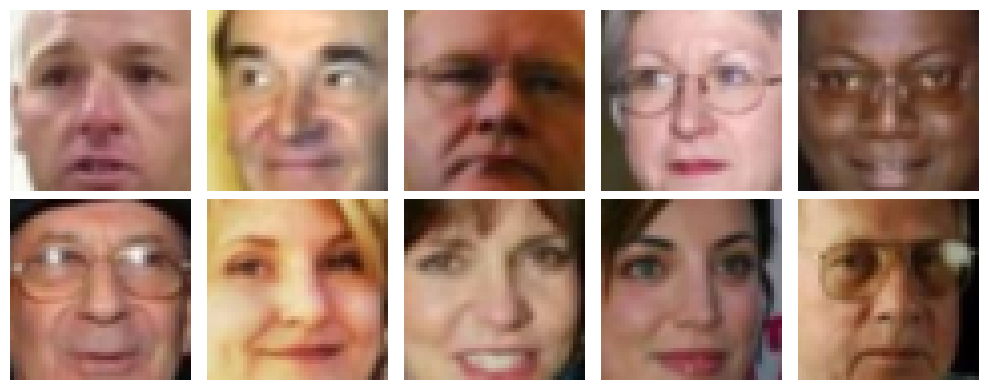

In [3]:
class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = self.dataframe.loc[index, "path"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # LFW deep-funneled images are 250x250. This reproduces the original
            # notebook's central crop while remaining safe for other image sizes.
            width, height = image.size
            margin_x = min(80, max(0, (width - 1) // 3))
            margin_y = min(80, max(0, (height - 1) // 3))
            image = image.crop((margin_x, margin_y, width - margin_x, height - margin_y))
            return self.transform(image)


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),  # pixel values in [0, 1]
])

train_df, val_df = train_test_split(image_df, test_size=0.2, random_state=SEED)
train_dataset = FaceDataset(train_df, transform)
val_dataset = FaceDataset(val_df, transform)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

faces = next(iter(train_loader))
assert faces.ndim == 4 and faces.shape[1:] == (3, 45, 45)
assert 0 <= faces.min() and faces.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(faces[:10], axes.flat):
    axis.imshow(face.permute(1, 2, 0))
    axis.axis("off")
plt.tight_layout()


## 2. From autoencoder to VAE (10 minutes)

A deterministic autoencoder maps $x$ to one vector $z$. A VAE encoder instead
describes a diagonal Gaussian approximate posterior:

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

We predict `logvar` rather than variance because it may take any real value and is
numerically convenient. For a batch of `N` images and `LATENT_DIM = 100`, answer:

1. What are the shapes of `mu`, `logvar`, and `z`?
2. Why must the final `mu` and `logvar` layers have no ReLU?
3. Why does directly drawing `z` from a distribution parameterized by the encoder
   make ordinary backpropagation difficult?

Write your answers in a new Markdown cell.


### Answers to the Section 2 questions

1. **Shapes.** `mu`, `logvar`, and `z` are all `(N, 100)`, that is `(N, LATENT_DIM)`. Each image gets its own mean and log-variance for each of the 100 latent dimensions, and `z` holds one sample from that distribution.
2. **No ReLU on the final layers.** A ReLU would clamp outputs to $[0,\infty)$. The mean of a Gaussian can be negative, and $\log\sigma^2$ must be negative whenever $\sigma^2<1$. With a ReLU, `logvar` could never go below 0, so $\sigma$ could never be smaller than 1, and `mu` could not use the negative half of the latent space.
3. **Why direct sampling blocks backpropagation.** Drawing $z\sim q_\phi(z\mid x)$ is a stochastic operation, so there is no ordinary derivative of the sampled value with respect to $\phi$, and the gradient cannot pass from the decoder back into the encoder. The reparameterization $z=\mu+\sigma\odot\epsilon$ with $\epsilon\sim\mathcal N(0,I)$ moves the randomness into an input that does not depend on $\phi$, which leaves $z$ a differentiable function of $\mu$ and $\sigma$.


## 3. Implement the probabilistic encoder (25 minutes)

**TODO 1:** Add two linear heads that map the shared 1000-unit representation to
`LATENT_DIM`: one for `mu` and one for `logvar`.

**TODO 2:** Implement the reparameterization trick. Compute
$\sigma=\exp(\tfrac12\log\sigma^2)$, draw $\epsilon$ with `torch.randn_like`, and
return $\mu+\sigma\epsilon$.

**TODO 3:** Complete `forward`: encode, sample, decode, and return
`reconstruction, mu, logvar`. The decoder returns probabilities in `[0, 1]`, so its
last operation is a sigmoid.


In [4]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )

        # TODO 1: two linear heads, with no activation, so both outputs can take any real value.
        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))
        return self.mu_head(features), self.logvar_head(features)

    def reparameterize(self, mu, logvar):
        # TODO 2: the randomness lives in epsilon, so gradients flow through mu and sigma.
        sigma = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(sigma)
        return mu + sigma * epsilon

    def decode(self, z):
        pixels = self.decoder(z)
        return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x):
        # TODO 3: encode x, sample z, decode it, and return all three outputs.
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


In [5]:
# These checks give fast feedback before expensive training.
model = DenseFaceVAE().to(DEVICE)
test_batch = faces[:4].to(DEVICE)
reconstruction, mu, logvar = model(test_batch)

assert reconstruction.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert reconstruction.min() >= 0 and reconstruction.max() <= 1

# Sampling should normally give different z values, while gradients still reach
# both distribution heads.
z1 = model.reparameterize(mu, logvar)
z2 = model.reparameterize(mu, logvar)
assert not torch.equal(z1, z2)
(z1.mean()).backward()
assert model.mu_head.weight.grad is not None
assert model.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("Model checks passed.")


Model checks passed.


## 4. Implement the negative ELBO (20 minutes)

For this Bernoulli observation model, minimize

$$
\mathcal L = \underbrace{\operatorname{BCE}(\hat x,x)}_{\text{reconstruction}}
+\beta\underbrace{D_{KL}\!\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)}_{\text{regularization}}.
$$

For a diagonal Gaussian,

$$D_{KL}=-\frac12\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

**TODO 4:** Compute BCE and KL with `reduction="sum"`, then divide each by the
batch size so reported values are per image. Return total loss, detached
reconstruction loss, and detached KL loss. Do not detach the total loss.


In [6]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
    # TODO 4: reconstruction + beta * KL, with both terms normalized per image.
    batch_size = target.size(0)
    reconstruction_term = F.binary_cross_entropy(reconstruction, target, reduction="sum") / batch_size
    kl_term = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    total = reconstruction_term + beta * kl_term
    return total, reconstruction_term.detach(), kl_term.detach()


In [7]:
# At mu=0 and logvar=0, q(z|x) equals the unit-normal prior, so KL must be zero.
dummy_x = torch.full((2, 3, 45, 45), 0.5, device=DEVICE)
dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
total, recon_term, kl_term = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(kl_term, torch.tensor(0.0, device=DEVICE))
assert total.requires_grad is False  # dummy tensors do not require gradients

# With model outputs, the total must carry a gradient path.
reconstruction, mu, logvar = model(test_batch)
total, _, _ = vae_loss(reconstruction, test_batch, mu, logvar, beta=BETA)
assert total.requires_grad
print("Loss checks passed.")


Loss checks passed.


## 5. Train the VAE (20–30 minutes)

**TODO 5:** Complete one training step: move the batch to the device, clear old
gradients, run the model, compute the VAE loss, backpropagate, and update parameters.

The reconstruction term sums over 6075 pixels, whereas KL sums over 100 latent
dimensions, so their magnitudes will differ. Track them separately. Ten epochs are a
starting point; reduce `EPOCHS` for a smoke test or increase it for better faces.


In [8]:
def train_step(model, batch, optimizer, beta):
    # TODO 5: one optimization step, returning three Python floats.
    batch = batch.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    reconstruction, mu, logvar = model(batch)
    total, reconstruction_term, kl_term = vae_loss(reconstruction, batch, mu, logvar, beta)
    total.backward()
    optimizer.step()
    return total.item(), reconstruction_term.item(), kl_term.item()


Epoch 01 | train 3984.83 | val 3924.20 | recon 3907.96 | KL 16.23


Epoch 02 | train 3895.15 | val 3890.56 | recon 3873.13 | KL 17.44


Epoch 03 | train 3860.22 | val 3869.65 | recon 3853.21 | KL 16.44


Epoch 04 | train 3843.67 | val 3826.43 | recon 3807.69 | KL 18.74


Epoch 05 | train 3828.63 | val 3827.78 | recon 3809.48 | KL 18.30


Epoch 06 | train 3822.77 | val 3843.82 | recon 3829.66 | KL 14.16


Epoch 07 | train 3817.37 | val 3808.42 | recon 3790.51 | KL 17.91


Epoch 08 | train 3809.92 | val 3809.42 | recon 3793.85 | KL 15.57


Epoch 09 | train 3803.07 | val 3833.39 | recon 3816.51 | KL 16.88


Epoch 10 | train 3802.36 | val 3794.69 | recon 3778.52 | KL 16.17


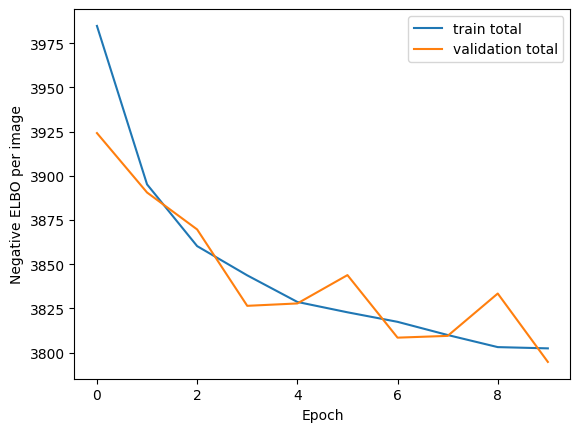

In [9]:
@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0
    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(reconstruction, batch, mu, logvar, beta)
        batch_size = batch.size(0)
        totals += np.array([value.item() for value in values]) * batch_size
        examples += batch_size
    return totals / examples


model = DenseFaceVAE().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"train_total": [], "val_total": [], "val_reconstruction": [], "val_kl": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_total = 0.0
    seen = 0
    for batch in train_loader:
        total, reconstruction_term, kl_term = train_step(model, batch, optimizer, BETA)
        running_total += total * batch.size(0)
        seen += batch.size(0)

    val_total, val_reconstruction, val_kl = evaluate(model, val_loader, BETA)
    history["train_total"].append(running_total / seen)
    history["val_total"].append(val_total)
    history["val_reconstruction"].append(val_reconstruction)
    history["val_kl"].append(val_kl)
    print(
        f"Epoch {epoch:02d} | train {running_total / seen:.2f} | "
        f"val {val_total:.2f} | recon {val_reconstruction:.2f} | KL {val_kl:.2f}"
    )

plt.plot(history["train_total"], label="train total")
plt.plot(history["val_total"], label="validation total")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO per image")
plt.legend()
plt.show()


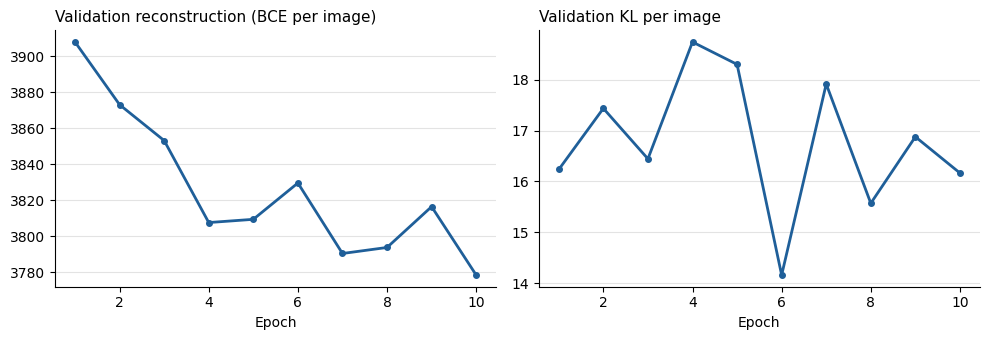

In [10]:
# The two loss terms have very different scales, so each gets its own panel.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
epochs_axis = range(1, EPOCHS + 1)
for axis, key, title in zip(
    axes,
    ["val_reconstruction", "val_kl"],
    ["Validation reconstruction (BCE per image)", "Validation KL per image"],
):
    axis.plot(epochs_axis, history[key], color="#1f5f99", linewidth=2, marker="o", markersize=4)
    axis.set_title(title, loc="left", fontsize=11)
    axis.set_xlabel("Epoch")
    axis.grid(axis="y", color="#e3e3e3")
    axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


**Learning curves.** Training loss fell every epoch, from 3984.83 to 3802.36. Validation reconstruction fell from 3907.96 to 3778.52, with some epoch-to-epoch noise. Validation KL stayed between about 14 and 19 with no clear trend, so most of the improvement came from the reconstruction term.


## 6. Inspect reconstructions (10 minutes)

For a repeatable reconstruction we decode the posterior mean rather than a random
sample. Compare identity, pose, colour, and fine detail. Dense networks discard
spatial structure when flattening, so some blur is expected.


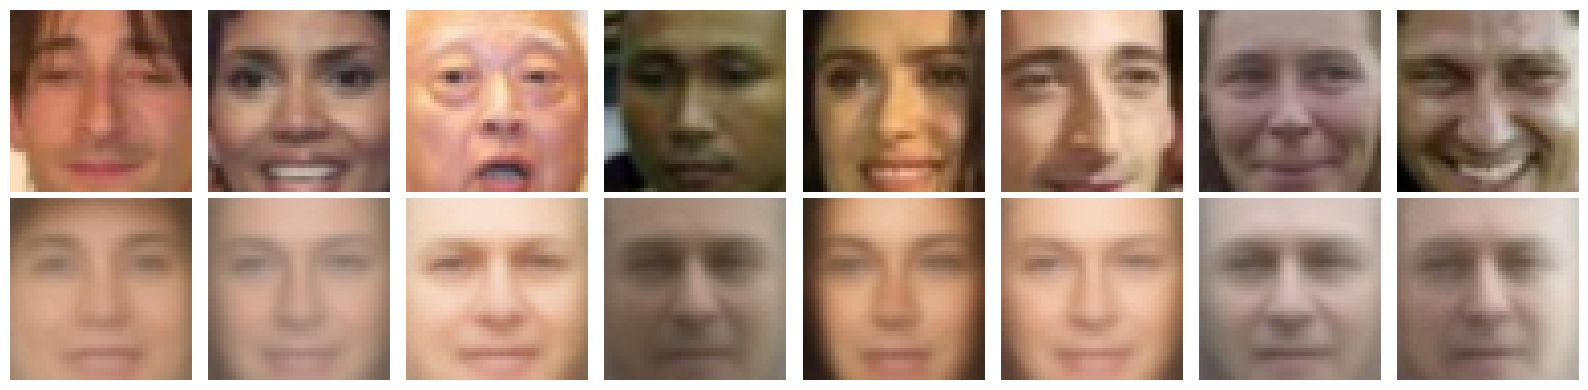

In [11]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu, _ = model.encode(validation_faces)
    reconstructed_faces = model.decode(mu)

originals = validation_faces.cpu()
reconstructed_faces = reconstructed_faces.cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for index in range(8):
    axes[0, index].imshow(originals[index].permute(1, 2, 0))
    axes[1, index].imshow(reconstructed_faces[index].permute(1, 2, 0).clamp(0, 1))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()


**Observations.** The top row shows the originals and the bottom row shows the reconstructions. The model recovers overall skin tone, lighting direction, and the rough position of the face. It loses identity and fine detail: hair, teeth, wrinkles, and backgrounds are smoothed away, and several different people come out looking similar. This is the blur expected from a dense network that flattens its input, here trained for only ten epochs.


## 7. Generate new faces (10 minutes)

Reconstruction conditions on an existing face. Generation does not: it draws from
the prior and sends those latent vectors directly to the decoder.

**TODO 6:** Sample 10 latent vectors from $\mathcal N(0,I)$ on `DEVICE`, decode them,
and store the result in `generated_faces`. Then run the visualization cell.


In [12]:
model.eval()
with torch.no_grad():
    # TODO 6: sample from the prior and decode.
    z = torch.randn(10, LATENT_DIM, device=DEVICE)
    generated_faces = model.decode(z)


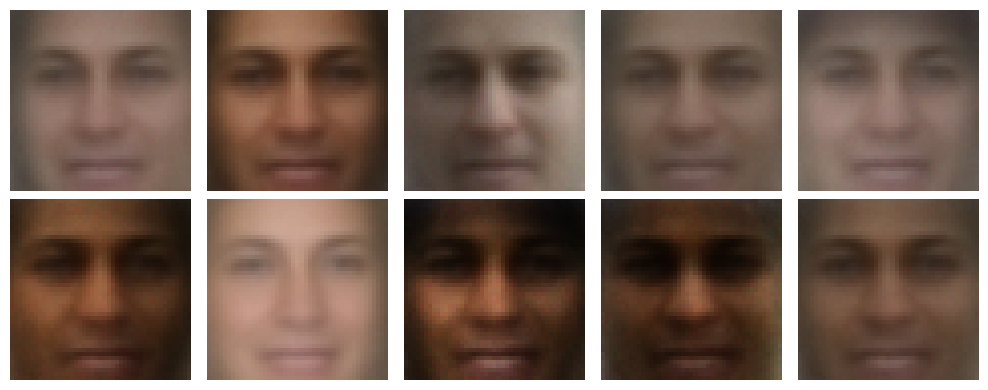

In [13]:
assert generated_faces.shape == (10, 3, 45, 45)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(generated_faces.cpu(), axes.flat):
    axis.imshow(face.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.tight_layout()


**Observations.** No input image was used here, yet every sample is recognisably a centred, front-facing face, with eyes, nose, and mouth in the right places. The samples vary in skin tone and lighting, but they are blurry and share a similar face shape, so they look closer to averaged faces than to distinct people.


## 8. Experiment: what does $\beta$ control? (15–30 minutes)

Train fresh models using two of `BETA = 0`, `0.1`, `1`, or `4`, keeping all other
settings fixed. Record validation reconstruction, validation KL, and visual quality
of prior samples.

| $\beta$ | Reconstruction | KL | Prior-sample observations |
|---:|---:|---:|---|
| | | | |
| | | | |

Answer in a Markdown cell:

1. What happens at $\beta=0$, and why is that model no longer encouraged to have a
   sampleable unit-normal latent space?
2. How does increasing $\beta$ change reconstruction fidelity and prior samples?
3. Why can a VAE be implemented without convolutional layers? What disadvantage does
   this dense model have for images?

### Optional extensions

- Interpolate between the posterior means of two validation faces and decode the path.
- Replace the dense encoder/decoder with convolutional layers without changing the
  probabilistic heads, reparameterization, or loss.
- Add KL warm-up: increase $\beta$ gradually from 0 to 1 during early epochs.


In [14]:
# Decode each JPEG once so repeated training runs do not spend their time on image loading.
# The images, split, and batch size are the same as in the main run.
def cache_faces(dataset):
    return torch.stack([dataset[index] for index in range(len(dataset))])


cached_train_loader = DataLoader(cache_faces(train_dataset), shuffle=True, **loader_args)
cached_val_loader = DataLoader(cache_faces(val_dataset), shuffle=False, **loader_args)


def train_fresh(beta, model_class=DenseFaceVAE, epochs=EPOCHS, warmup_epochs=0):
    """Train a new model from the same seed and return it with its validation metrics."""
    torch.manual_seed(SEED)
    run_model = model_class().to(DEVICE)
    run_optimizer = torch.optim.Adam(run_model.parameters(), lr=LEARNING_RATE)
    for epoch in range(epochs):
        # With warm-up, beta rises linearly from 0 and reaches its target after warmup_epochs.
        epoch_beta = beta * min(1.0, epoch / warmup_epochs) if warmup_epochs else beta
        run_model.train()
        for batch in cached_train_loader:
            train_step(run_model, batch, run_optimizer, epoch_beta)
    torch.manual_seed(SEED)  # every run is scored with the same posterior noise
    total, reconstruction_term, kl_term = evaluate(run_model, cached_val_loader, beta)
    return run_model, {"reconstruction": reconstruction_term, "kl": kl_term, "total": total}


torch.manual_seed(SEED)
prior_z = torch.randn(10, LATENT_DIM, device=DEVICE)  # the same latents for every model
comparison_faces = next(iter(cached_val_loader))[:10].to(DEVICE)


def show_rows(rows, row_height=1.3):
    """Draw a grid of images with one labelled row per (label, images) pair."""
    fig, axes = plt.subplots(len(rows), 10, figsize=(13, row_height * len(rows)), squeeze=False)
    for row_axes, (label, images) in zip(axes, rows):
        for axis, image in zip(row_axes, images.cpu()):
            axis.imshow(image.permute(1, 2, 0).clamp(0, 1))
            axis.set_xticks([])
            axis.set_yticks([])
        row_axes[0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def prior_samples(run_model):
    run_model.eval()
    return run_model.decode(prior_z)


@torch.no_grad()
def mean_reconstructions(run_model):
    run_model.eval()
    return run_model.decode(run_model.encode(comparison_faces)[0])


In [15]:
BETAS = [0.0, 0.1, 1.0, 4.0]
beta_models, beta_rows = {}, []
for beta in BETAS:
    beta_models[beta], metrics = train_fresh(beta)
    beta_rows.append({"beta": beta, **metrics})
    print(f"beta={beta:<4} | recon {metrics['reconstruction']:.2f} | KL {metrics['kl']:.2f}")

beta_results = pd.DataFrame(beta_rows).set_index("beta").round(2)
beta_results


beta=0.0  | recon 3757.01 | KL 284.33


beta=0.1  | recon 3771.69 | KL 61.81


beta=1.0  | recon 3780.41 | KL 16.03


beta=4.0  | recon 3788.82 | KL 8.06


,reconstruction,kl,total
beta,,,
0.0,3757.01,284.33,3757.01
0.1,3771.69,61.81,3777.87
1.0,3780.41,16.03,3796.44
4.0,3788.82,8.06,3821.06


Prior samples: each column uses the same z for every beta


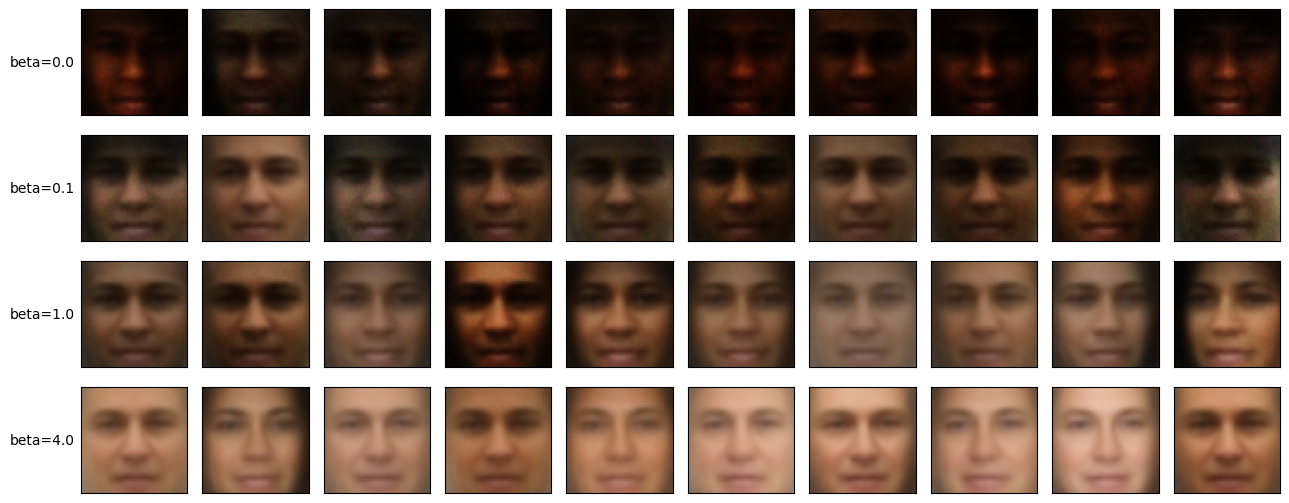

In [16]:
print("Prior samples: each column uses the same z for every beta")
show_rows([(f"beta={beta}", prior_samples(beta_models[beta])) for beta in BETAS])


Reconstructions of validation faces, decoded from the posterior mean


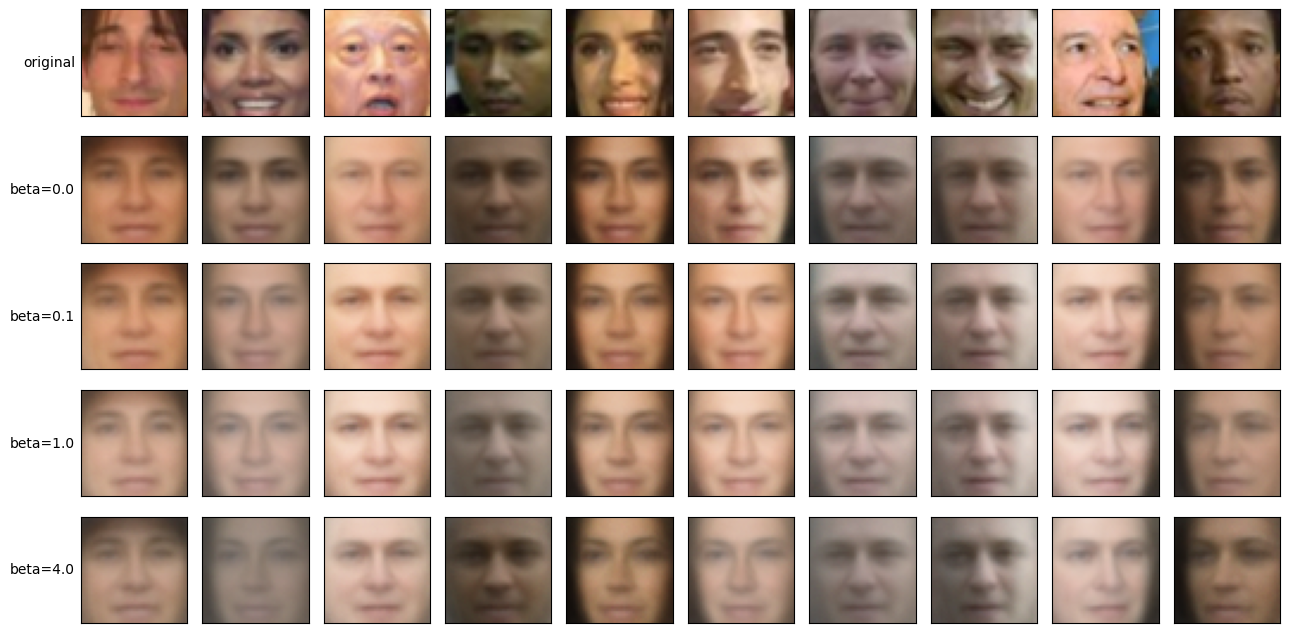

In [17]:
print("Reconstructions of validation faces, decoded from the posterior mean")
show_rows(
    [("original", comparison_faces)]
    + [(f"beta={beta}", mean_reconstructions(beta_models[beta])) for beta in BETAS]
)


### Results of the $\beta$ experiment

I ran all four values rather than the required two. Each model used the same seed, split, and ten epochs. Values are per image on the validation set.

| $\beta$ | Reconstruction | KL | Negative ELBO ($\beta=1$ weighting) | Prior-sample observations |
|---:|---:|---:|---:|---|
| 0 | 3757.01 | 284.33 | 4041.34 | Very dark, grainy, and almost identical to each other, with only a faint face |
| 0.1 | 3771.69 | 61.81 | 3833.50 | Clearly faces, but dark and grainy, with some variety in skin tone |
| 1 | 3780.41 | 16.03 | 3796.44 | Coherent faces with more variety in tone and lighting, and less grain |
| 4 | 3788.82 | 8.06 | 3796.88 | Smoothest and brightest, but very blurry and all close to one average face |

The `total` column in the code output uses each model's own $\beta$, so it cannot be compared across rows. The negative ELBO column adds reconstruction and KL with equal weight, which makes the rows comparable. By that measure, $\beta=1$ and $\beta=4$ are almost tied, and both are well ahead of $\beta=0$ and $\beta=0.1$.

### Answers to the Section 8 questions

**1. What happens at $\beta=0$?** The KL term drops out, so the loss is reconstruction only, and nothing pulls $q_\phi(z\mid x)$ towards $\mathcal N(0,I)$. The encoder can place its codes wherever they help reconstruction, and the KL grew to 284.33, compared with 16.03 at $\beta=1$. The decoder is trained only on the regions the encoder actually uses, so a draw from $\mathcal N(0,I)$ can land where it has had little training. That matches the result: $\beta=0$ had the best reconstruction (3757.01) but the worst prior samples, which were dark, noisy, and nearly identical. It behaves much like a deterministic autoencoder with noise added.

**2. How does increasing $\beta$ change reconstruction and prior samples?** As $\beta$ rose from 0 to 4, reconstruction loss rose from 3757.01 to 3788.82 while KL fell from 284.33 to 8.06. A stronger KL penalty limits how much information $z$ can carry about each image, so reconstructions keep less individual detail. Prior samples became cleaner and more coherent because the latent codes match the prior more closely. Pushed too far, the samples lose variety: at $\beta=4$ they are smooth but all resemble one average face. In this run, $\beta=1$ gave the best balance of coherence and variety. The KL changed far more than the reconstruction in relative terms, partly because BCE on non-binary pixels has a high minimum value that no model can get below.

**3. Why can a VAE be dense, and what is the disadvantage?** A VAE is defined by its probabilistic model, not its layer type: an encoder that outputs a distribution, the reparameterized sample, a decoder, and the ELBO objective. Any differentiable network can produce those outputs, including linear layers. The disadvantage is that flattening discards which pixels are neighbours. A dense network shares no weights across positions, so it must learn a feature separately at each location, and small shifts in a face are hard for it to handle. It also needs many parameters: this model has about 21.5 million, of which about 18.2 million are in the two layers connected to the pixels. The convolutional extension below supports this, reaching a lower reconstruction loss with the same training budget.


## Optional extensions

All three extensions from Section 8 are below. The runs use the same seed, split, and epoch count as the $\beta$ experiment.

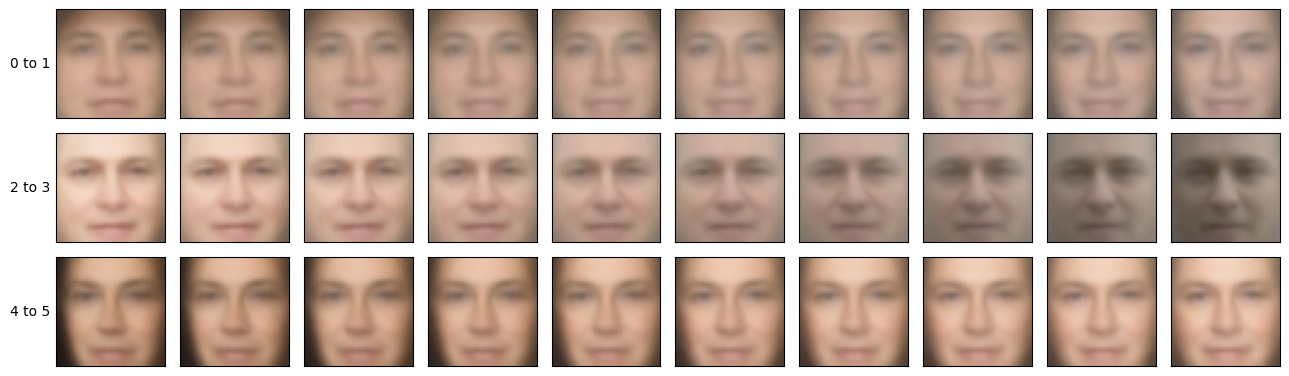

In [18]:
# Extension 1: walk in a straight line between the posterior means of two validation faces.
baseline = beta_models[1.0]
baseline.eval()
pairs = [(0, 1), (2, 3), (4, 5)]
rows = []
with torch.no_grad():
    means = baseline.encode(comparison_faces)[0]
    for start, end in pairs:
        weights = torch.linspace(0, 1, 10, device=DEVICE).unsqueeze(1)
        path = (1 - weights) * means[start] + weights * means[end]
        rows.append((f"{start} to {end}", baseline.decode(path)))
show_rows(rows)


,reconstruction,kl,total
"dense, beta=1",3780.41,16.03,3796.44
"dense, beta=1 with KL warm-up",3779.60,15.53,3795.13
"convolutional, beta=1",3728.16,25.10,3753.26


Reconstructions


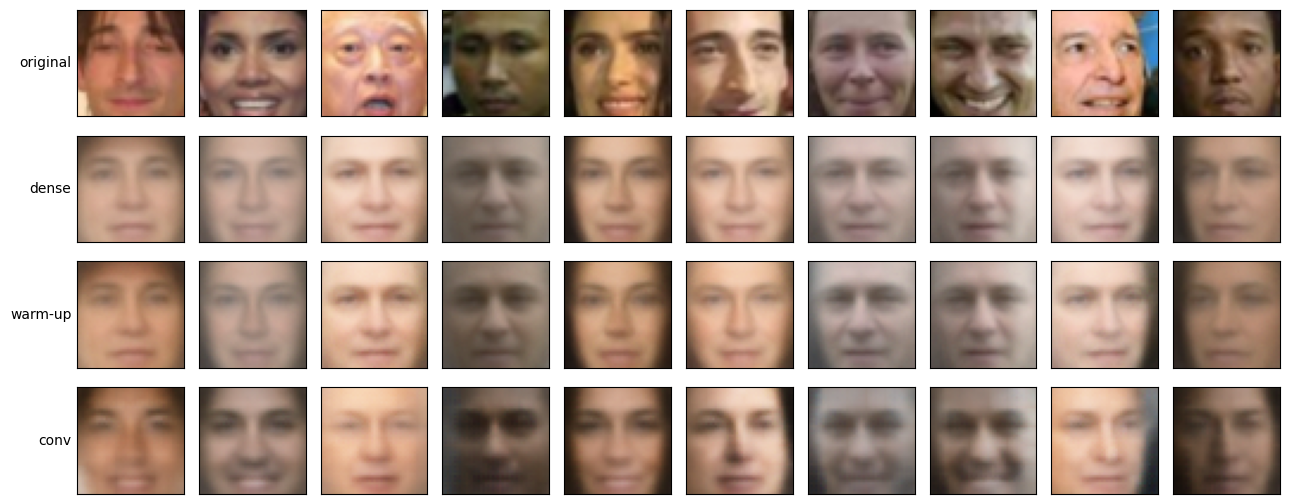

Prior samples


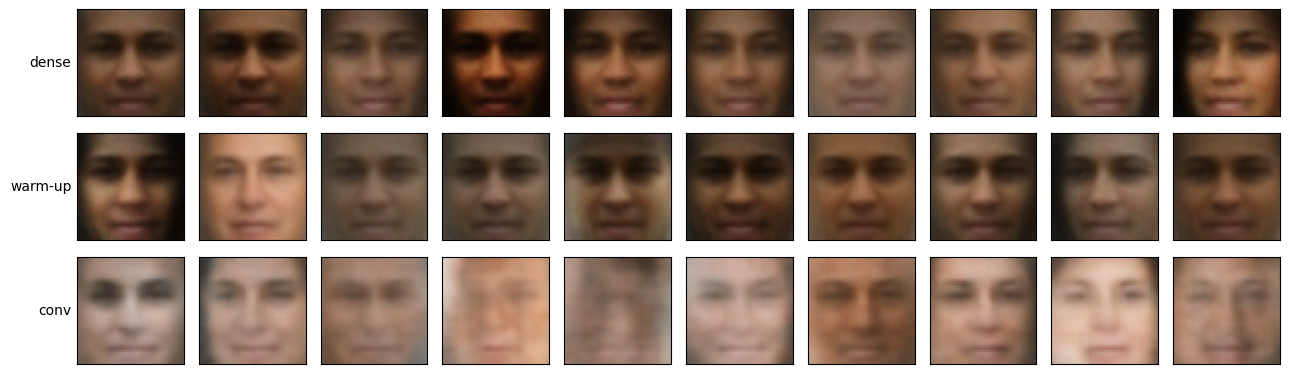

In [19]:
# Extension 2: convolutional encoder and decoder. The heads, reparameterization, forward
# pass, and loss are all inherited unchanged from DenseFaceVAE.
class ConvFaceVAE(DenseFaceVAE):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__(input_dim, latent_dim)
        self.encoder = nn.Sequential(
            nn.Conv2d(CHANNELS, 32, 3, stride=2, padding=1),  # 45 -> 23
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),  # 23 -> 12
            nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1),  # 12 -> 6
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 1000),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 6 * 6),
            nn.ReLU(),
            nn.Unflatten(1, (128, 6, 6)),
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1),  # 6 -> 12
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1),  # 12 -> 23
            nn.ReLU(),
            nn.ConvTranspose2d(32, CHANNELS, 3, stride=2, padding=1),  # 23 -> 45
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x)  # keep the spatial layout: no flatten here
        return self.mu_head(features), self.logvar_head(features)


# Extension 3: KL warm-up on the dense model, with beta reaching 1 after 5 epochs.
warmup_model, warmup_metrics = train_fresh(1.0, warmup_epochs=5)
conv_model, conv_metrics = train_fresh(1.0, model_class=ConvFaceVAE)

extension_results = pd.DataFrame(
    {
        "dense, beta=1": beta_results.loc[1.0],
        "dense, beta=1 with KL warm-up": warmup_metrics,
        "convolutional, beta=1": conv_metrics,
    }
).T.round(2)
display(extension_results)

print("Reconstructions")
show_rows([
    ("original", comparison_faces),
    ("dense", mean_reconstructions(beta_models[1.0])),
    ("warm-up", mean_reconstructions(warmup_model)),
    ("conv", mean_reconstructions(conv_model)),
])
print("Prior samples")
show_rows([
    ("dense", prior_samples(beta_models[1.0])),
    ("warm-up", prior_samples(warmup_model)),
    ("conv", prior_samples(conv_model)),
])


### Extension results

Values are per image on the validation set, with the total at $\beta=1$.

| Model | Reconstruction | KL | Total |
|---|---:|---:|---:|
| Dense | 3780.41 | 16.03 | 3796.44 |
| Dense with KL warm-up | 3779.60 | 15.53 | 3795.13 |
| Convolutional | 3728.16 | 25.10 | 3753.26 |

- **Interpolation.** The decoded path changes smoothly in skin tone, lighting, and face shape, with no sudden jumps or broken images in between. That is evidence of a continuous latent space. The endpoints are blurry reconstructions, so the path moves between average-looking faces and does not preserve identity.
- **Convolutional model.** This was the clear improvement, with a total about 43 lower than the dense model. Its reconstructions keep more contrast and structure, including some smiles and shading. Its prior samples vary more but are less consistent: a few are smeared and barely look like faces, so ten epochs may not be enough for this model.
- **KL warm-up.** The final metrics are almost the same as the dense model without warm-up, a difference of about 1 in total. Some reconstructions keep slightly more colour, but this single run shows no meaningful benefit. The KL at $\beta=1$ was not collapsing to zero to begin with, so there was little for warm-up to fix.


## Submission and assessment

Submit the executed student notebook with:

- probabilistic encoder heads and correct tensor shapes (**1 mark**);
- reparameterization and forward pass, with checks passing (**2 marks**);
- reconstruction-plus-KL loss, with checks passing (**2 marks**);
- training step and recorded learning curves (**2 marks**);
- reconstructions and generated faces (**1 mark**); and
- the $\beta$ experiment and conceptual answers (**2 marks**).

**Total: 10 marks.**
